## Homework 3 - Analysis Using the $p$, $np$, $c$, and $u$ Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 16, 2026 via D2L**

## Instructions:

Ravi's Comics and Games is a local comic book and tabletop game shop that receives weekly new-release shipments from a regional distributor. Ravi's customers, especially the collectors chasing near-mint copies, have started complaining more often about comics arriving with scratched or folded covers, and Ravi has noticed it's starting to hurt sales of his higher-end back issues too. He's asked your quality control team to help him figure out how bad the problem really is, whether it's getting better or worse, and who -- the distributor, or his own shop -- is responsible.

Your team decides to look at this two different ways. First, every comic in a week's shipment gets a quick pass/fail condition check as staff unbox and shelve it (any visible scratch, crease, or fold on the cover marks it nonconforming). Because the number of comics in a shipment varies week to week depending on the new-release schedule, your team tracks both the **rate** of nonconforming comics (useful for spotting trends) and the **raw count** (useful when Ravi calls the distributor's account representative, who thinks in terms of "how many books," not percentages).

Second, your team recognizes that a single comic can have more than one distinct defect on it -- a scratch on the front cover **and** a folded corner on the back, for example -- so a simple pass/fail check doesn't capture the full severity of the damage. To get a fuller picture, staff also perform a more detailed defect count each week, counting every individual scratch, fold, or dent they find (not just how many comics have at least one). This detailed count is done on two separate parts of the shop: a **fixed** sample of 5 boxes pulled from the new-release shipment every week, and a **variable** number of already-shelved back-issue boxes, inspected whenever staff have the time.

## Key Specifications

| Quantity | Value |
|---|---|
| Nonconforming definition (Datasets A) | Any visible scratch, crease, or fold on the cover |
| Nonconformity definition (Datasets B & C) | Each individual scratch, fold, or dent found (a comic may have more than one) |
| Dataset A: Shipment Condition, Phase I weeks (m) | 25 weeks, variable shipment size |
| Dataset A: Shipment Condition, Phase II weeks (m) | 20 weeks, variable shipment size |
| Dataset B: New-Release Defect Counts, weeks (m) | 25 weeks, fixed sample of 5 boxes/week |
| Dataset C: Back-Issue Defect Counts, weeks (m) | 25 weeks, variable number of boxes/week |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

### Answer:  The purpose of the analysis is to measure how bad the comicbook damage problem is for the shop, how bad is the issue, and whether or not it is improving, stable, or getting worse. Also, we need to figure out if it is a problem at the shop or with the distributor. We will build the Phase I chart from the data and use those limits to check if the Phase II chart is in control or not.

### Q2: Ravi's team is monitoring two distinct quality characteristics here: a pass/fail condition check, and a detailed defect count. For each, classify the type of attribute data being collected, and briefly explain how this differs from the continuous, normally-distributed data used in your previous two homeworks.

### Answer: The pass/fail condition is binary data so that should follow a Binomial distribtution. For the detailed defect count a single comic can have multiple defects this data would be modeled with a Poisson distribution.  The previous assignments we have used data that is measured on a continous scale and assumed to be normally distributed which a pass/fail is not and neither is count attribute data.

### Q3: For the pass/fail data (Dataset A), what practical factor determines whether you should build a $p$ chart or an $np$ chart? For the detailed defect-count data (Datasets B and C), what practical factor determines whether you should build a $c$ chart or a $u$ chart?

### Answer: For dataset A it all breaks down to whether or not the number of comics received by the shop is the same each week or not, which we know they are not the same each week.  Becasue of this fact the $p$ chart would be the preferred chart to use since the $p$ chart would put each week on the same scale.  For datasets B, it would be more practical to use a $c$ chart because they always inspect 5 boxes so the total counts are comparable.  A $u$ chart would be more practical for dataset C sice the number of boxes changes each week, so the data needs to be normalized.

## Analyze

### Q4: Read the Phase I Shipment Condition data (Dataset A) into R. Construct a Phase I $p$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

### Answer: The phase I control chart is not in control. Week 14 is the out of control point in the chart. There can be any number of reasons for this issue.  It could be the boxes were crushed, or they could have been dropped during shipping from the distributor.  The distributor themselves could have poorly packed the boxes leading to the damage.

In [3]:
## Clone forked repository to Colab ##

## Specify your GitHub username:
user_name <- "Bishop13"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive for HW1:

setwd("STAT-7110-Quality-Control//Assignments//HW3")## Q4 Code ##

In [5]:
install.packages(c("tidyverse", "readxl", "qcc"))

## Load the libraries ##

library(tidyverse)
library(readxl)
library(qcc)

## Read in the Phase I Data ##

phase1 <- read_excel("RavisComics_ShipmentCondition_PhaseI.xlsx")
phase2 <- read_excel("RavisComics_ShipmentCondition_PhaseII.xlsx")

#phase_1<- as.matrix(phase1[, c("TotalComics","NumberNonconforming")])

dim(phase1)
dim(phase2)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



[1] 25  3

[1] 20  3

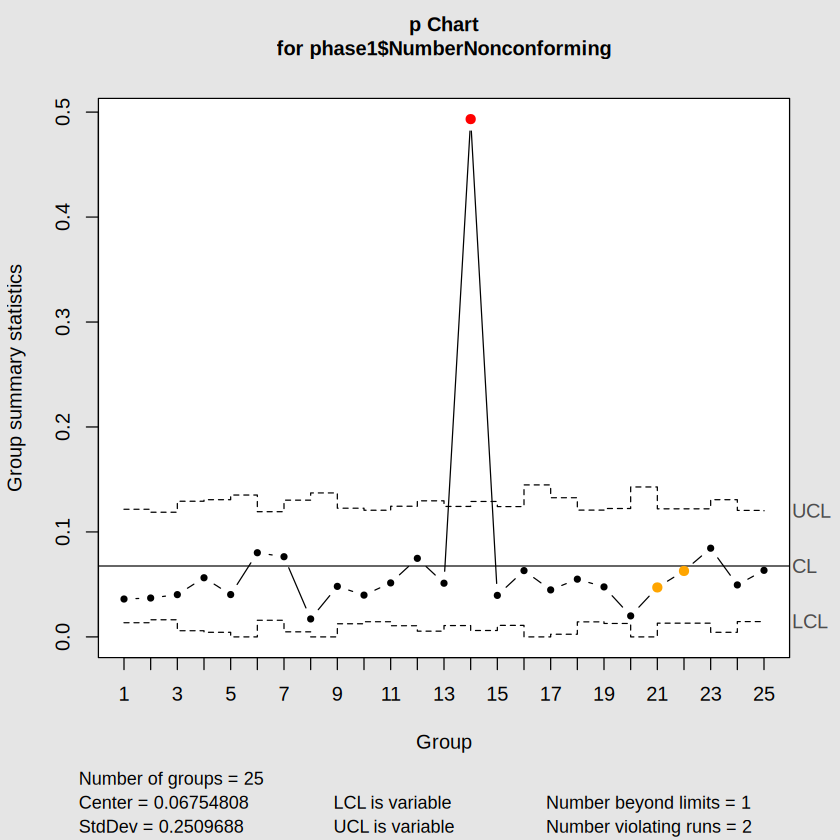

In [7]:
# Phase I p chart with variable shipment sizes
ship_chart <- qcc(phase1$NumberNonconforming,
                  type = "p",
                  sizes = phase1$TotalComics,
                  plot = TRUE)

Week,TotalComics,NumberNonconforming
<dbl>,<dbl>,<dbl>
14,150,74


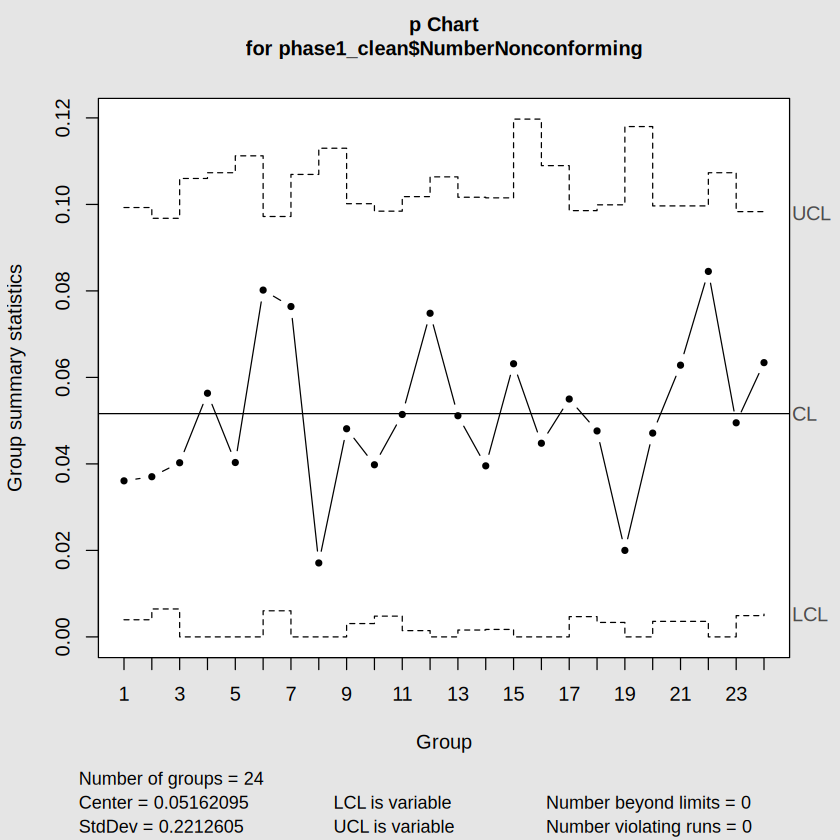

In [12]:
ooc_points <- ship_chart$violations$beyond.limits
phase1[ooc_points, ]          # confirm which week is out of control

phase1_clean <- phase1[-ooc_points, ]

ship_chart1 <- qcc(phase1_clean$NumberNonconforming,
                   type = "p",
                   sizes = phase1_clean$TotalComics,
                   plot = TRUE)

### Q5: Repeat the analysis in Q4, this time constructing an $np$ chart on the same data. Do your conclusions about which week(s) are out of control change? Which chart do you think would be easier to explain to the distributor's account representative, and why?

### Answer: The conclusions do not change, week 14 is still out of control in the $np$ chart. As well as week 21 and 22 violating the rules. If I was to show both charts to the rep the $np$ chart would look the scariest to the rep because of how busy it looks. However, the $np$ chart would be easier to explain in terms of how a rep would think. It would be easier to explain for week 14 that 74 of the 150 arrived damaged then to speak about the proportion.

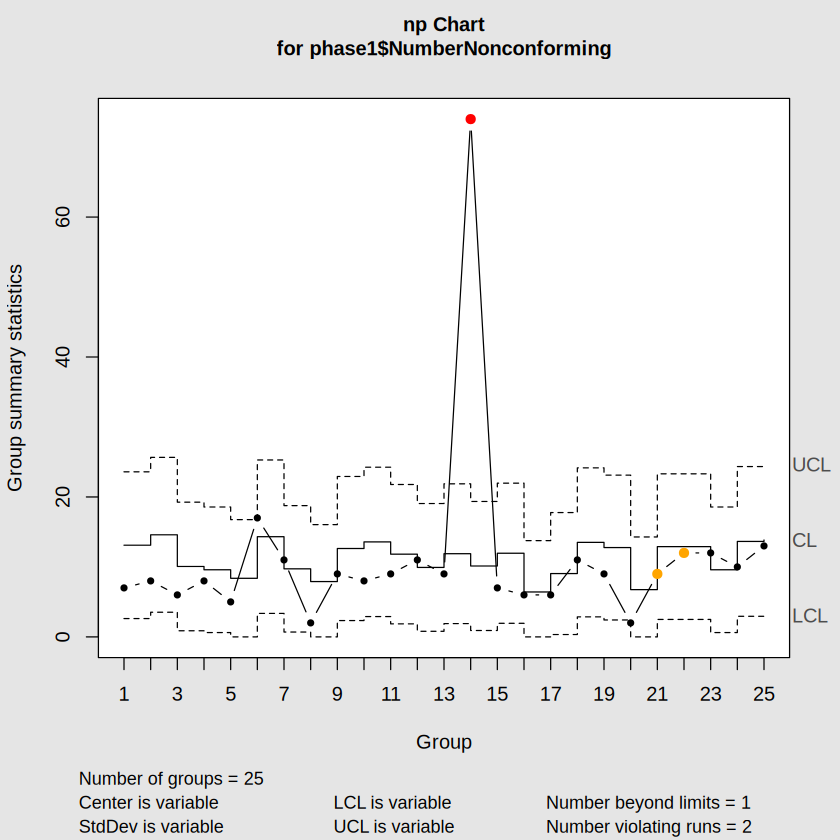

In [11]:
# Phase I np chart
ship_np <- qcc(phase1$NumberNonconforming,
               type = "np",
               sizes = phase1$TotalComics,
               plot = TRUE)

Week,TotalComics,NumberNonconforming
<dbl>,<dbl>,<dbl>
14,150,74


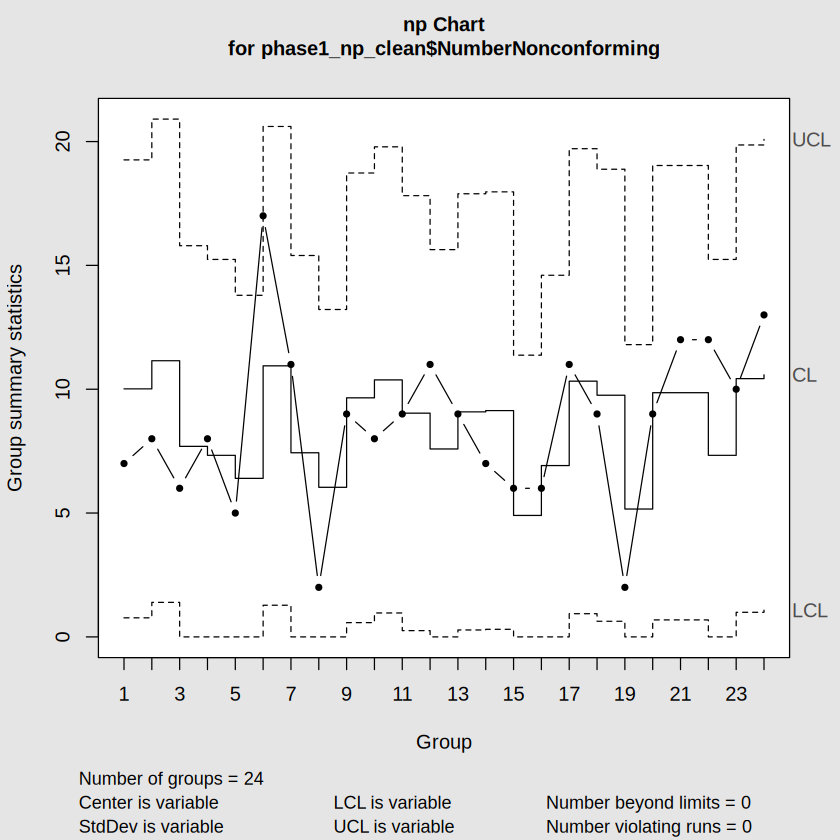

In [13]:
ooc_np <- ship_np$violations$beyond.limits
phase1[ooc_np, ]

phase1_np_clean <- phase1[-ooc_np, ]

ship_np1 <- qcc(phase1_np_clean$NumberNonconforming,
                type = "np",
                sizes = phase1_np_clean$TotalComics,
                plot = TRUE)

### Q6: Using your finalized Phase I estimate of $\bar{p}$, report the center line and control limits you will carry forward into Phase II.

In [37]:
ship_chart1$limits

,LCL,UCL
,0.003964205,0.09927769
,0.006456330,0.09678557
,0.000000000,0.10600006
,0.000000000,0.10732426
,0.000000000,0.11123030
,0.006032239,0.09720966
,0.000000000,0.10693608
,0.000000000,0.11298758
,0.003080429,0.10016147
,0.004801403,0.09844049


In [38]:
ship_chart1$limits

uclp <- ship_chart1$limits[, "UCL"]
lclp <- ship_chart1$limits[, "LCL"]
pbar <- ship_chart1$center

pbar

,LCL,UCL
,0.003964205,0.09927769
,0.006456330,0.09678557
,0.000000000,0.10600006
,0.000000000,0.10732426
,0.000000000,0.11123030
,0.006032239,0.09720966
,0.000000000,0.10693608
,0.000000000,0.11298758
,0.003080429,0.10016147
,0.004801403,0.09844049


[1] 0.05162095

## Improve

### Q7: After seeing your Phase I results, Ravi calls the distributor, who agrees to add cardboard stiffeners to every shipping box going forward. Briefly explain why it would not be appropriate to use your *original* (uncleaned) Phase I control limits, rather than the finalized limits from Q6, to judge whether this packaging fix actually worked.

### Answer:  It would not be appropriate because week 14 increased $\bar{p}$ from a baseline of 0.0508 to 0.068 and also widened the control limits.  That makes the chart less sensitive. Meaning, this would make it more difficult to show if the process is in control or not.

## Control

### Q8: Read the Phase II Shipment Condition data into R. Using your finalized Phase I center line and control limits from Q6, construct the Phase II $p$ chart. Do any weeks plot outside the control limits? Does this support the conclusion that the packaging fix worked?

### Answer: Week 2 does plot outside the control limit but that limit is the lower control limit.  In this case that is a good thing.  It also appears that after week 5 the average units damaged are all below the established $\bar{p}$.  This chart would support the conclusion that the fix performed by the distributor has worked.

Warning message in statistics > ucl:
“longer object length is not a multiple of shorter object length”
Warning message in statistics < lcl:
“longer object length is not a multiple of shorter object length”


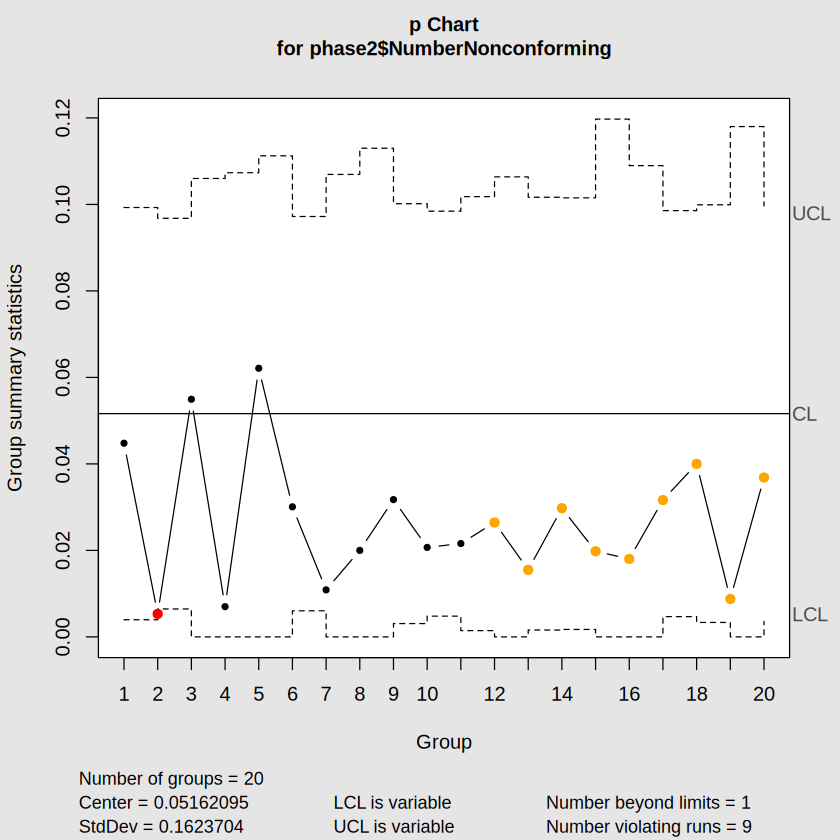

In [39]:
## Pass only the Phase I center; qcc builds each week's limits from that week's n_i ##
ship_chartp2 <- qcc(phase2$NumberNonconforming,
               type = "p",
               sizes = phase2$TotalComics,
               limits = c(lclp,uclp),
               center = pbar,
               plot = TRUE)

### Q9: Repeat Q8 using an $np$ chart instead. Is your conclusion consistent with Q8?

### Answer: Yes, it is consistent with Q8.

In [40]:
ship_np1$limits

uclnp <- ship_np1$limits[, "UCL"]
lclnp <- ship_np1$limits[, "LCL"]
npbar <- ship_np1$center
npbar

,LCL,UCL
,0.7690558,19.25987
,1.3945672,20.90568
,0.0000000,15.79401
,0.0000000,15.24005
,0.0000000,13.79256
,1.2788347,20.60845
,0.0000000,15.39880
,0.0000000,13.21955
,0.5760402,18.73019
,0.9650819,19.78654


[1] 10.014464 11.150125  7.691521  7.330175  6.400998 10.943641  7.433416
 [8]  6.039651  9.653117 10.375810  9.033666  7.588279  9.085287  9.136908
[15]  4.903990  6.917207 10.324190  9.756359  5.162095  9.859601  9.859601
[22]  7.330175 10.427431 10.582294

Warning message in statistics > ucl:
“longer object length is not a multiple of shorter object length”
Warning message in statistics < lcl:
“longer object length is not a multiple of shorter object length”
Warning message in statistics - center:
“longer object length is not a multiple of shorter object length”


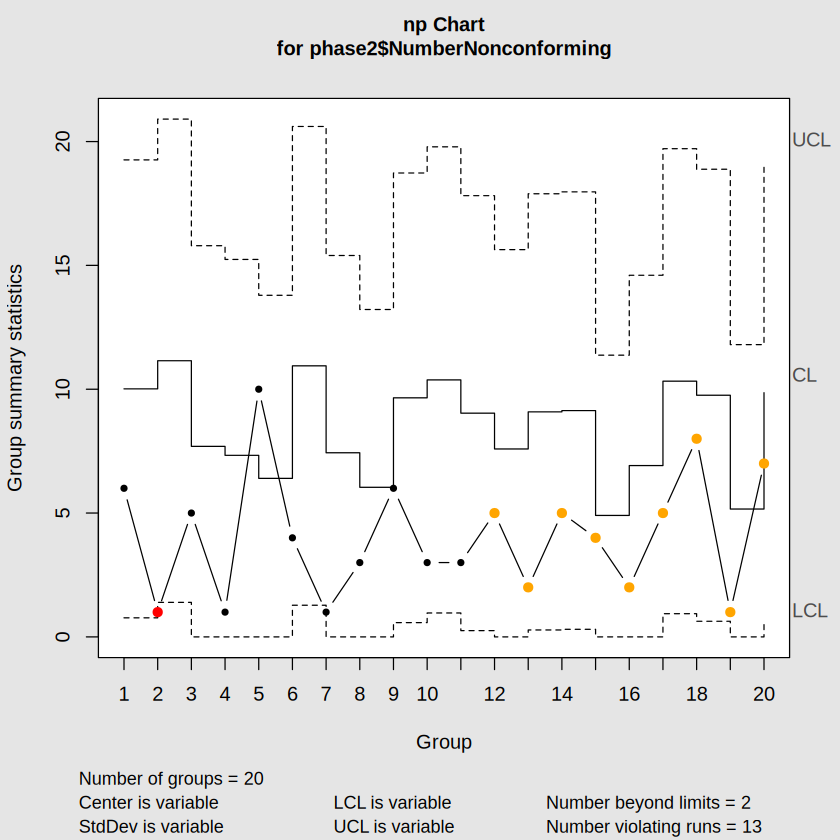

In [42]:
ship_np2 <- qcc(phase2$NumberNonconforming,
                        type="np",
                        sizes=phase2$TotalComics,
                        limits = c(lclnp, uclnp),
                        center = npbar,
                        plot=TRUE)

### Q10: Read the New-Release Defect Counts data (Dataset B) into R. Construct a $c$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

### Answer: The $c$ chart show that it is not in control.  Week 8 is out of control and shows 52 defects in the 5-box sample.  This damage most likely done before the boxes arrived to the shop. This could be a result of the distributor mishandling the boxes/comics or the damage happened during shipping.

In [43]:
newrel <- read_xlsx("RavisComics_NewReleaseDefectCounts.xlsx")
dim(newrel)


[1] 25  3

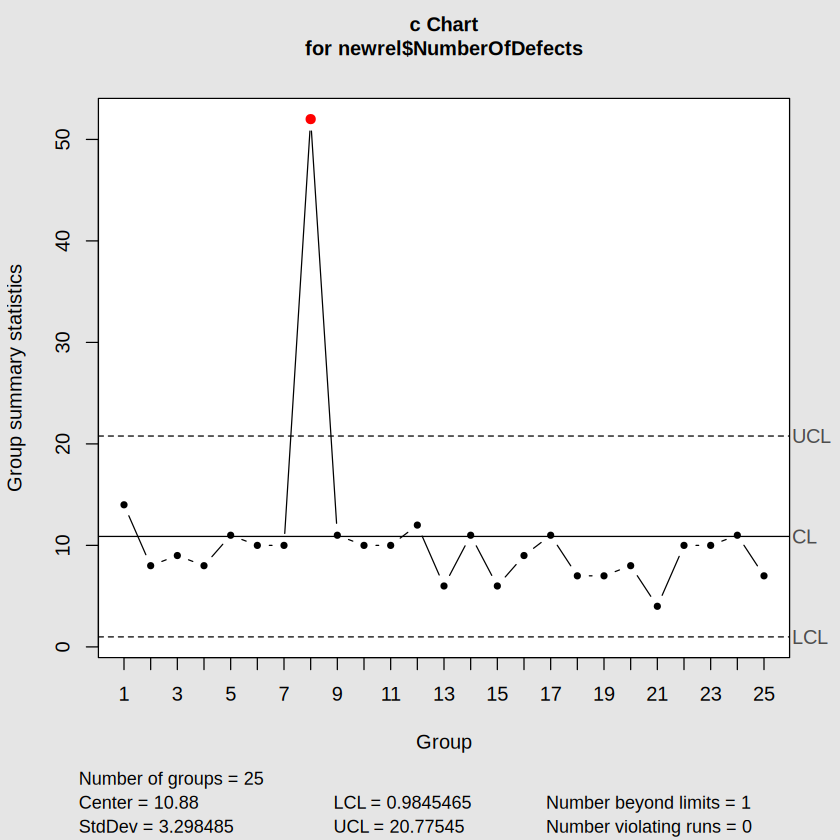

In [44]:
newrel_chart <- qcc(newrel$NumberOfDefects,
                    type = "c",
                    plot = TRUE)

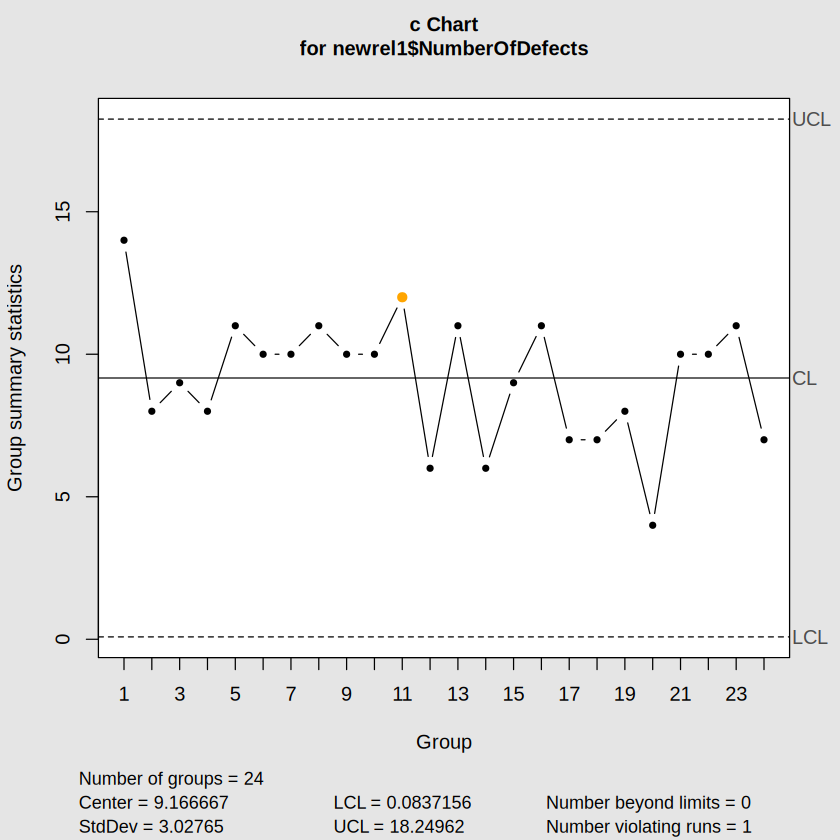

In [45]:
ooc_c <- newrel_chart$violations$beyond.limits


newrel1 <- newrel[-ooc_c, ]
newrel_chart1 <- qcc(newrel1$NumberOfDefects, type = "c", plot = TRUE)

### Q11: Using your finalized $c$ chart, report $\bar{c}$ and the control limits. In 1-2 sentences, explain what this chart tells Ravi that the Q4-Q9 pass/fail analysis could not.

### Answer: This chart measures how much damage per comic there is not just if a comic is damaged or not. This tracks severity of damage not just how many defective comics in a box.

In [46]:
newrel_chart1$center
newrel_chart1$limits

[1] 9.166667

,LCL,UCL
,0.0837156,18.24962


### Q12: Read the Back-Issue Defect Counts data (Dataset C) into R. Construct a $u$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

### Answer: The chart is not in control. Week 17 has approximately 5.5 defects per box. This would point to the shop being the cause of the defects.  The possible causes are frequent handling by customers/careless customers, or employees being careless when placing them on the shelves.

In [47]:
backiss <- read_xlsx("RavisComics_BackIssueDefectCounts.xlsx")
dim(backiss)

[1] 25  3

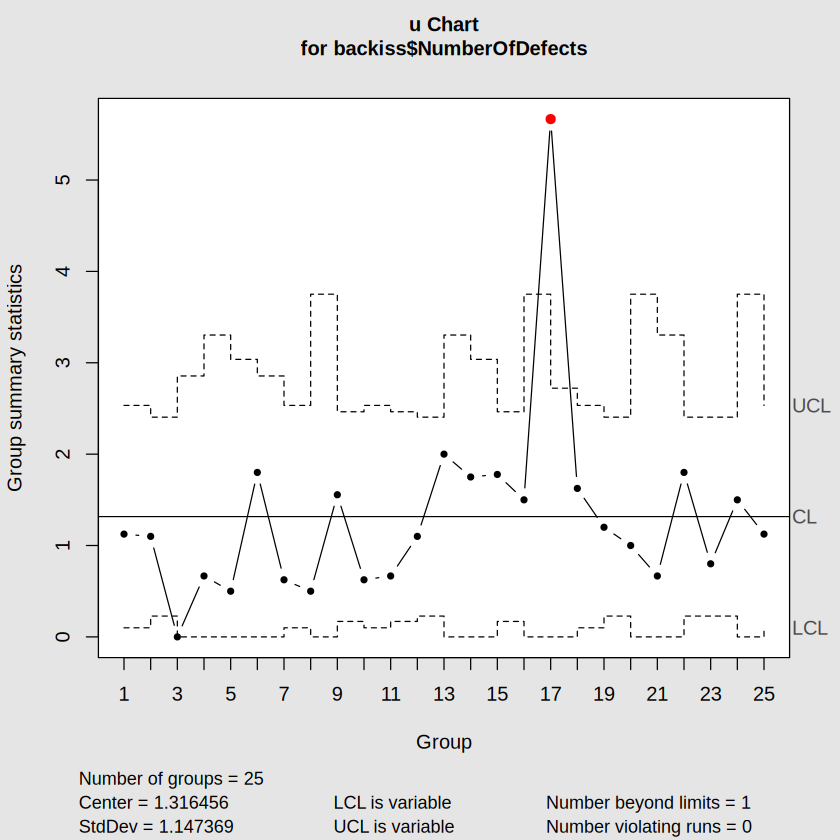

In [48]:
backiss_chart <- qcc(backiss$NumberOfDefects,
                     type = "u",
                     sizes = backiss$BoxesInspected,
                     plot = TRUE)

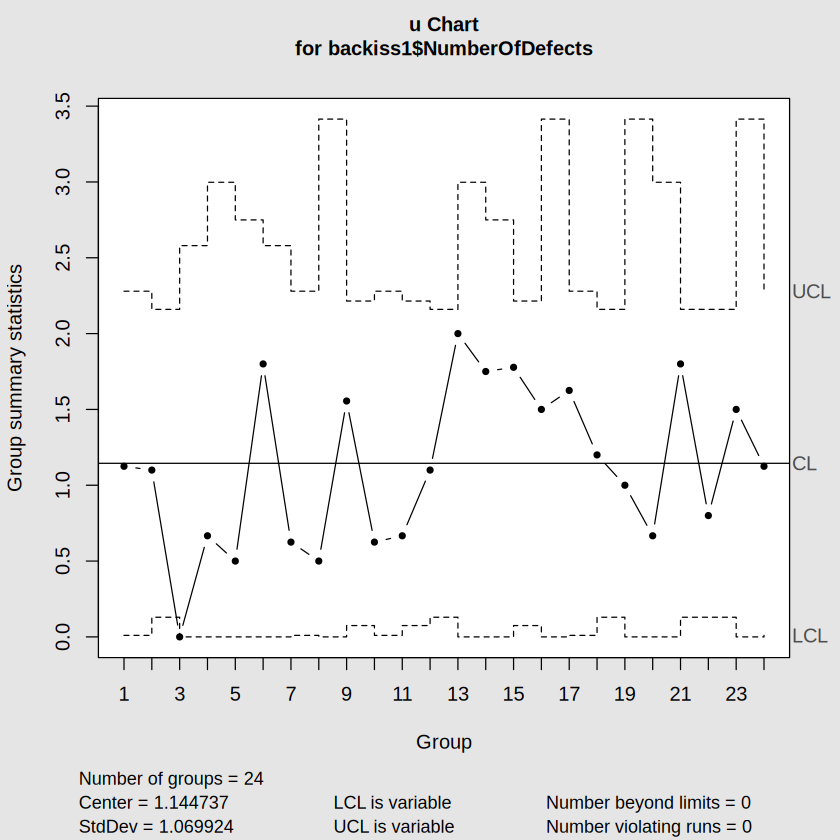

In [49]:
ooc_u <- backiss_chart$violations$beyond.limits

backiss1 <- backiss[-ooc_u, ]
backiss_chart1 <- qcc(backiss1$NumberOfDefects,
                      type = "u",
                      sizes = backiss1$BoxesInspected,
                      plot = TRUE)

### Q13: Suppose you tried to build a $c$ chart on the Back-Issue Defect Counts data instead of a $u$ chart. Why would this not be an appropriate choice, given how the data were collected?

### Answer: The $c$ chart would not be appropriate because the number of inspections are not the same.  The number of inspected boxes range from 2 - 10.  It was basically left up to the employees on how many to inspect.

### Q14: Provide an overview of your results that Ravi can use the next time he calls the distributor's account representative. Citing specific evidence from your $p$/$np$ analysis **and** your $c$/$u$ analysis, which parts of the damage problem look like they're the distributor's responsibility, and which parts (if any) look more like an internal, in-shop handling issue?

### Answer: This analysis points to the distributor as the responsible party for the damages. Before the fix approximately 5.2% of the comics wre damaged.  After the fix that dropped to approximately 2.7%. The defect count also tells the same basic story that the number of defects was reduced after the distributor implemented the fix.  The back issue damage is the responsibility of the shop.  Back issues on the shelves had about 1.1 defects/box and week 17 it jumped to 5.7/box which happened entirely in store.